# 07 CNN图像分类与RNN歌词生成


本篇对应 **day07**，是「06-深度学习神经网络」7篇笔记中的第7篇。承接06的卷积与池化，先完成CNN图像分类的训练、测试和推理，再学习词嵌入、循环神经网络，以及按字符生成歌词短句的完整流程。

资料：[深度学习神经网络课程资料](https://pan.baidu.com/s/1FPhKS2qMBgnqVOXCyhBTog?pwd=1234)，提取码 `1234`。已核对 `04_深度学习神经网络/视频/day07` 的 **17个视频文件标题**。教师 `课堂笔记.zip`、`课件.zip`、课程代码和原始数据正文未取得，视频未逐段转录；本文按已核对的目录组织，讲解、代码和图示均独立编写。

CNN示例使用scikit-learn自带的手写数字小数据集，RNN示例使用本篇自编的短句语料；两者都不是课程原数据，实验数值也不是教师课堂成绩。全部内容为Markdown单元，Python代码块按顺序复制到代码单元即可运行。**所有图片直接嵌入本Notebook附件，无需其他图片文件。**


## 本篇学习路线

| 视频范围 | 核心问题 | 本篇完成的工作 |
| --- | --- | --- |
| 01 | 今天学习什么 | 从图像分类过渡到序列生成 |
| 02–07 | CNN如何完成图像分类 | 数据划分、搭建网络、训练、测试、调优与保存 |
| 08 | RNN为什么有隐藏状态 | 把前文信息传到后续时间步 |
| 09–10 | token ID如何变成可学习向量 | Embedding查表、形状与参数 |
| 11–12 | RNN层接收和返回什么 | 输入、输出、最终隐藏状态与batch_first |
| 13–17 | 歌词生成怎样落地 | 词表、滑动窗口、训练、逐字符生成与温度采样 |

完成后应能解释两条数据流：

- 图像 → 卷积特征 → 分类logits → 类别。
- token ID → 嵌入向量 → RNN隐藏状态 → 下一token的logits → 生成文字。

CNN主要利用图像的空间邻近关系；RNN通过隐藏状态处理序列的顺序关系。这是两种归纳偏置，不意味着CNN只能处理图像、RNN只能处理文字。


## 1. 环境与运行顺序

示例全部使用CPU，不下载图片或歌词。`load_digits()`直接读取scikit-learn随包提供的数据。复制代码时按本文顺序执行，后面的代码会复用前面的变量。

```bash
python -m pip install torch numpy scikit-learn matplotlib
```

```python
import copy
import io
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

SEED = 2026
torch.manual_seed(SEED)
torch.set_num_threads(2)
device = torch.device("cpu")
print("PyTorch:", torch.__version__, "device:", device)
```

固定种子帮助复现实验，跨版本和硬件仍可能存在差异。若后续改用GPU，应把输入、标签和模型移动到同一设备；本篇的验证记录只代表CPU运行。


## 2. CNN数据集：先确认像素、通道和标签

手写数字数据集含1797张8×8灰度图，类别为0–9。像素范围是0–16，**不是0–255**。按数据说明除以16即可缩放到0–1；这个固定缩放规则不依赖验证集或测试集的统计量。

```python
digits = load_digits()
images = digits.images.astype(np.float32) / 16.0
labels = digits.target.astype(np.int64)
class_names = [str(i) for i in range(10)]

print("images:", images.shape, images.dtype,
      "range:", (images.min(), images.max()))
print("labels:", labels.shape, labels.dtype)
assert images.shape == (1797, 8, 8)
assert labels.min() == 0 and labels.max() == 9
```

PyTorch的`Conv2d`默认接收 **NCHW**：批量、通道、高、宽。灰度图通道数为1，输入应是`(N,1,8,8)`；标签为`(N,)`，类型为`torch.long`。一张灰度图不是RGB图，不能直接交给`in_channels=3`的网络。

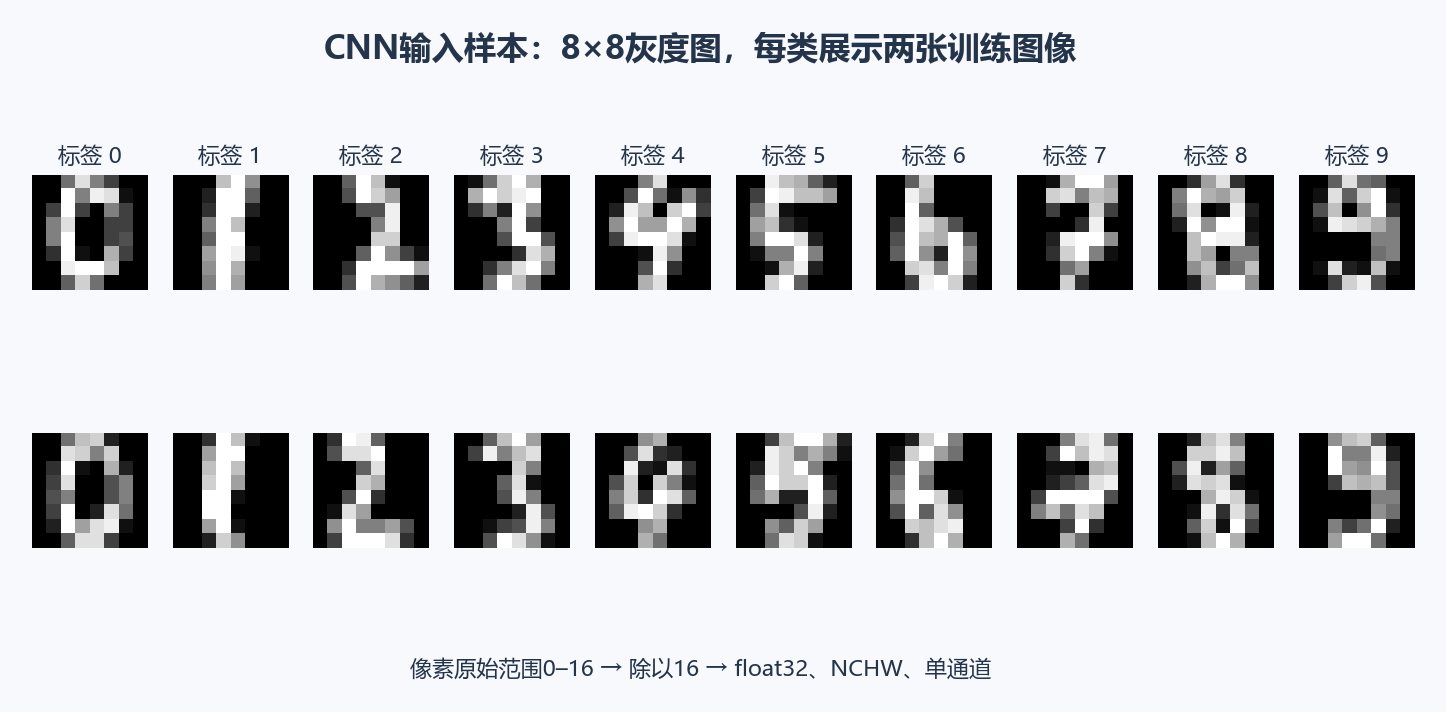

图中样本取自本例训练集，每列对应一个数字类别。8×8仅适合快速演示，真实图像分类还需处理分辨率、光照、背景和类别分布变化。


## 3. 划分训练、验证和测试集

保持各划分类别比例大致一致：训练集60%，验证集20%，测试集20%。**模型只用训练集更新参数，用验证集选择轮次，最后用测试集评估一次。**

```python
all_idx = np.arange(len(labels))
train_idx, holdout_idx = train_test_split(
    all_idx, test_size=0.4, random_state=SEED, stratify=labels
)
val_idx, test_idx = train_test_split(
    holdout_idx, test_size=0.5, random_state=SEED,
    stratify=labels[holdout_idx]
)

def make_image_dataset(indices):
    x = torch.from_numpy(images[indices]).unsqueeze(1)
    y = torch.from_numpy(labels[indices])
    return TensorDataset(x, y)

train_ds = make_image_dataset(train_idx)
val_ds = make_image_dataset(val_idx)
test_ds = make_image_dataset(test_idx)
train_loader = DataLoader(
    train_ds, batch_size=64, shuffle=True,
    generator=torch.Generator().manual_seed(SEED)
)
val_loader = DataLoader(val_ds, batch_size=128, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=128, shuffle=False)

assert set(train_idx).isdisjoint(val_idx)
assert set(train_idx).isdisjoint(test_idx)
assert set(val_idx).isdisjoint(test_idx)
assert len(train_idx) + len(val_idx) + len(test_idx) == len(labels)
xb, yb = next(iter(train_loader))
print("split:", len(train_ds), len(val_ds), len(test_ds))
print("batch:", tuple(xb.shape), tuple(yb.shape), yb.dtype)
```

真实数据按图像随机切分不一定足够。如果同一人的照片、同一视频的邻近帧或同一原图的增强版本分散到不同集合，可能出现泄漏，应按人物、来源或时间分组切分。数据增强只用于训练集；验证和测试预处理应稳定一致。


## 4. CNN结构：保留局部特征，再输出10类logits

本例使用两组卷积、ReLU和池化。第二次池化后保留2×2空间信息，再交给分类器。`AdaptiveAvgPool2d((2,2))`固定分类器前的空间尺寸；它不负责修复通道错误，也不能让前面池化层接受任意小输入。

| 操作 | 单个批次输出shape | 作用 |
| --- | --- | --- |
| 输入 | `(B,1,8,8)` | 灰度像素 |
| Conv2d(1,16,3,padding=1) + ReLU | `(B,16,8,8)` | 提取局部模式 |
| MaxPool2d(2) | `(B,16,4,4)` | 下采样 |
| Conv2d(16,32,3,padding=1) + ReLU | `(B,32,4,4)` | 组合局部特征 |
| MaxPool2d(2) | `(B,32,2,2)` | 再下采样 |
| AdaptiveAvgPool2d((2,2)) + Flatten | `(B,128)` | 固定分类器输入 |
| Linear(128,64) + ReLU + Linear(64,10) | `(B,10)` | 输出每类logits |

```python
class DigitCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((2, 2)),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 2 * 2, 64),
            nn.ReLU(),
            nn.Linear(64, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

torch.manual_seed(SEED)
cnn = DigitCNN().to(device)
with torch.no_grad():
    shape_x = torch.zeros(2, 1, 8, 8, device=device)
    for layer in cnn.features:
        shape_x = layer(shape_x)
        print(type(layer).__name__, tuple(shape_x.shape))
    demo_logits = cnn(torch.zeros(2, 1, 8, 8, device=device))
assert demo_logits.shape == (2, 10)
print("parameters:", sum(p.numel() for p in cnn.parameters()))
```

卷积层可训练参数量：`C_out × (C_in × K_h × K_w + 1)`，其中1来自每个输出通道的偏置。第一层为160，第二层为4640；两层Linear为8256和650，总计13706。ReLU、MaxPool和AdaptiveAvgPool都没有可训练参数。


## 5. 训练循环：交叉熵接收logits

多分类损失使用`CrossEntropyLoss`。输入为未经Softmax的`(B,10)` logits，标签为类别ID。损失内部已经完成相关的对数归一化，训练前再做Softmax会改变优化问题。

一个批次依次执行：清空梯度 → 前向计算 → 损失 → 反向传播 → 更新参数。训练集每轮打乱，验证集保持稳定。

```python
cnn_loss_fn = nn.CrossEntropyLoss()
cnn_optimizer = torch.optim.Adam(cnn.parameters(), lr=1e-3)

def train_cnn_epoch(model, loader, optimizer):
    model.train()
    loss_sum, correct, count = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = cnn_loss_fn(logits, y)
        loss.backward()
        optimizer.step()
        n = y.numel()
        loss_sum += loss.item() * n
        correct += (logits.argmax(dim=1) == y).sum().item()
        count += n
    return {"loss": loss_sum / count, "accuracy": correct / count}

@torch.inference_mode()
def evaluate_cnn(model, loader):
    model.eval()
    loss_sum, correct, count = 0.0, 0, 0
    targets, predictions = [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        pred = logits.argmax(dim=1)
        loss_sum += cnn_loss_fn(logits, y).item() * y.numel()
        correct += (pred == y).sum().item()
        count += y.numel()
        targets.append(y.cpu())
        predictions.append(pred.cpu())
    return {
        "loss": loss_sum / count, "accuracy": correct / count,
        "targets": torch.cat(targets).numpy(),
        "predictions": torch.cat(predictions).numpy(),
    }
```

这里将batch平均损失乘以batch样本数后累计，再除以总样本数。直接平均各batch损失会让较小的最后一个batch拥有过大的权重。`eval()`切换层的行为，`inference_mode()`关闭梯度记录，两者承担不同工作。


## 6. 用验证集选择权重

训练40轮，每轮仅查看训练集与验证集。保存验证损失最小的参数副本。`model.state_dict()`中的张量会随模型继续训练而变化，因此本例使用`copy.deepcopy`留存最佳权重。

```python
CNN_EPOCHS = 40
cnn_history = []
cnn_best = {"loss": float("inf"), "epoch": 0, "state": None}
for epoch in range(1, CNN_EPOCHS + 1):
    train_metrics = train_cnn_epoch(cnn, train_loader, cnn_optimizer)
    val_metrics = evaluate_cnn(cnn, val_loader)
    cnn_history.append({
        "epoch": epoch,
        "train_loss": train_metrics["loss"],
        "train_accuracy": train_metrics["accuracy"],
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
    })
    if val_metrics["loss"] < cnn_best["loss"]:
        cnn_best = {
            "loss": val_metrics["loss"], "epoch": epoch,
            "state": copy.deepcopy(cnn.state_dict()),
        }
    if epoch == 1 or epoch % 10 == 0:
        print(epoch, "train loss:", round(train_metrics["loss"], 4),
              "val loss:", round(val_metrics["loss"], 4),
              "val accuracy:", round(val_metrics["accuracy"], 4))

cnn.load_state_dict(cnn_best["state"])
print("selected epoch:", cnn_best["epoch"])
```

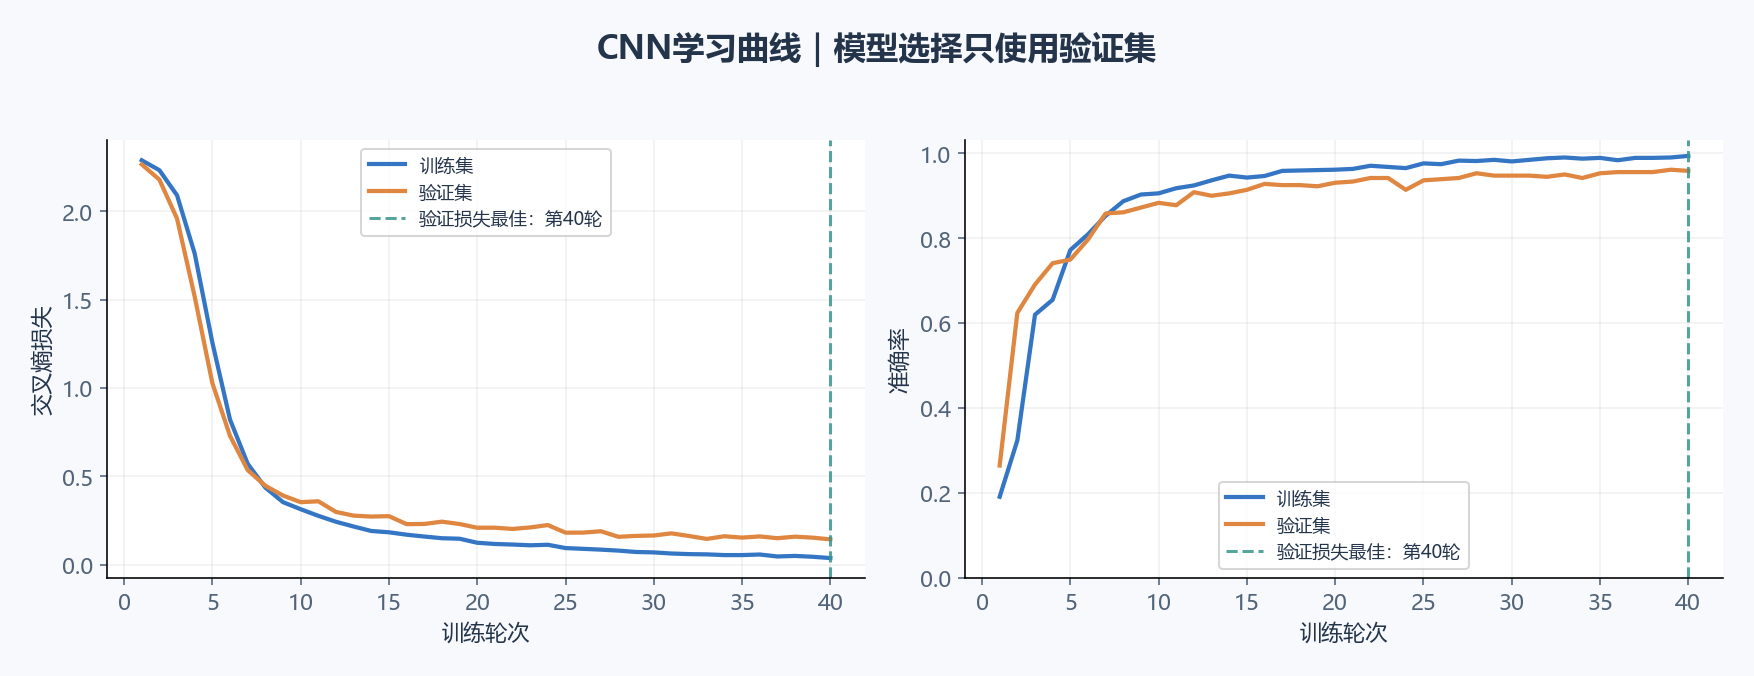

曲线来自上述代码的实际运行。训练准确率持续上升而验证损失反弹，通常提示过拟合或置信度变得过强；仅比较准确率可能看不到这个问题。最佳轮次由验证损失决定，不一定是最后一轮。


## 7. 最终测试：总准确率与混淆矩阵一起看

选好模型后再计算测试结果。混淆矩阵的**行是真实类别，列是预测类别**。对角线代表预测正确，其他格子说明哪些数字容易混淆。

```python
cnn_test = evaluate_cnn(cnn, test_loader)
cnn_cm = confusion_matrix(
    cnn_test["targets"], cnn_test["predictions"], labels=np.arange(10)
)
print("test loss:", round(cnn_test["loss"], 4))
print("test accuracy:", round(cnn_test["accuracy"], 4))
print(classification_report(
    cnn_test["targets"], cnn_test["predictions"],
    labels=np.arange(10), target_names=class_names,
    digits=3, zero_division=0,
))
assert cnn_cm.sum() == len(test_ds)
assert np.trace(cnn_cm) / cnn_cm.sum() == cnn_test["accuracy"]
```

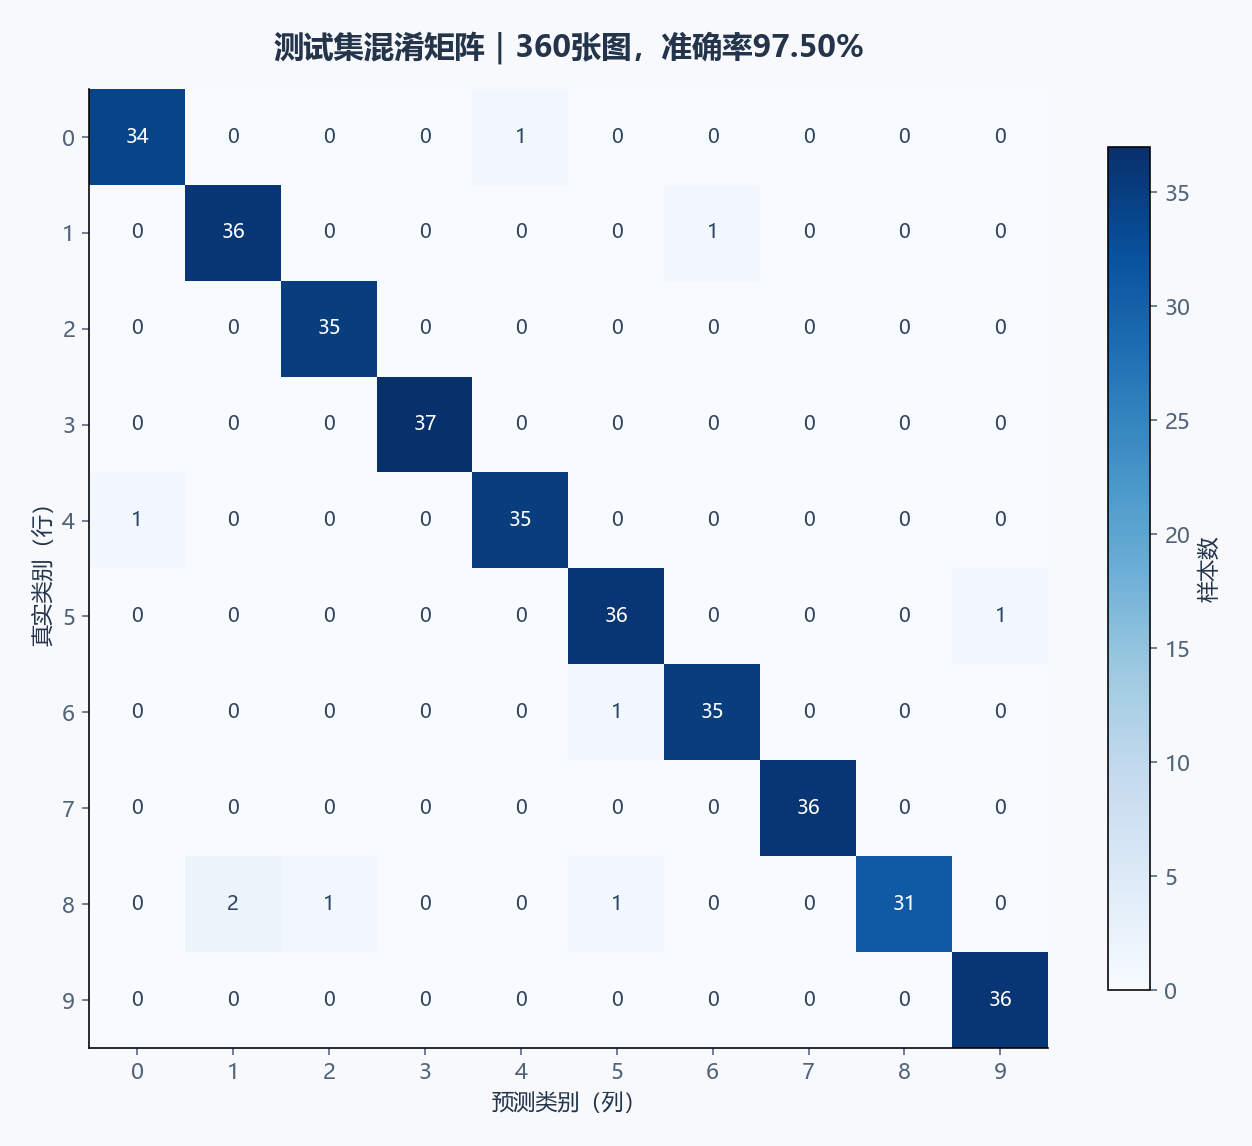

precision关注预测为某类的样本有多少是真的，recall关注真实属于某类的样本找回多少，F1结合两者。类别不均衡时，总准确率可能掩盖少数类别的问题，可同时看各类recall与macro F1。

测试集评估后如果又依据它反复调参，它就参与了模型选择，需要额外保留最终评估数据。本篇测试成绩只描述这个小数据集上的一次划分。


## 8. 保存模型，也保存预处理和类别映射

只保存权重不足以保证推理正确：还需要网络配置、像素缩放规则和类别名称。本例使用内存字节流展示保存/加载，避免生成额外文件；实际项目可把相同checkpoint写到本地路径。

```python
cnn_checkpoint = {
    "state_dict": {k: v.detach().cpu() for k, v in cnn.state_dict().items()},
    "config": {"num_classes": 10},
    "class_names": class_names,
    "preprocess": {"channels": 1, "height": 8, "width": 8,
                   "pixel_scale": 16.0},
    "selected_epoch": cnn_best["epoch"],
}
cnn_buffer = io.BytesIO()
torch.save(cnn_checkpoint, cnn_buffer)
cnn_buffer.seek(0)
loaded_cnn = torch.load(cnn_buffer, map_location="cpu", weights_only=True)
restored_cnn = DigitCNN(**loaded_cnn["config"]).eval()
restored_cnn.load_state_dict(loaded_cnn["state_dict"])

@torch.inference_mode()
def predict_digit(raw_image, model, checkpoint):
    spec = checkpoint["preprocess"]
    raw = np.asarray(raw_image, dtype=np.float32)
    if raw.shape != (spec["height"], spec["width"]):
        raise ValueError("本模型要求8×8灰度图")
    if not np.isfinite(raw).all() or raw.min() < 0 or raw.max() > spec["pixel_scale"]:
        raise ValueError("像素必须是0–16范围内的有限数值")
    x = torch.from_numpy(raw / spec["pixel_scale"])[None, None]
    model.eval()
    probabilities = model(x).softmax(dim=1)[0]
    class_id = int(probabilities.argmax())
    return checkpoint["class_names"][class_id], float(probabilities[class_id])

sample_idx = int(test_idx[0])
pred_name, confidence = predict_digit(digits.images[sample_idx], restored_cnn, loaded_cnn)
print("true:", labels[sample_idx], "pred:", pred_name,
      "softmax score:", round(confidence, 4))
with torch.inference_mode():
    probe = test_ds.tensors[0][:8]
    assert torch.allclose(cnn.eval()(probe), restored_cnn(probe), atol=1e-6)
```

这里的score是模型给出的Softmax分数，不是经过校准的正确概率。手机拍摄的0–255照片与digits数据的分辨率、背景和书写风格不同，不能只除以16后直接套用；应建立符合目标场景的数据和预处理流程。


## 9. CNN调优：先定位问题，再改配置

| 现象 | 优先检查 | 可以尝试的调整 |
| --- | --- | --- |
| 训练损失不下降 | 标签、输入范围、梯度、logits shape | 降低学习率，先尝试拟合一小批数据 |
| 训练和验证都很差 | 数据难度、网络容量、训练轮次 | 适当增大网络或训练轮次，检查预处理 |
| 训练好、验证差 | 泄漏、数据分布、过拟合 | 更可靠切分，训练增强，weight decay，早停 |
| 验证曲线剧烈波动 | 学习率、验证集大小 | 降低学习率，扩大验证集，重复固定实验 |
| 总准确率高但部分类别差 | 各类样本量和混淆矩阵 | 补充难例，调整采样或类别权重 |
| 加载后预测变化 | 模型模式与预处理 | 核对结构、权重、类别映射、缩放和eval模式 |

一次只改变少量因素并记录验证结果。旋转和翻转是否保持标签取决于任务：手写数字的某些旋转会改变类别，不能照搬自然图像的增强方案。

本篇已学习CNN训练流程。下面把“输入是一张图、输出一个类别”改成“输入一串token、每个位置预测下一个token”。


## 10. RNN：把前面的信息放进隐藏状态

普通前馈层每次只处理当前输入；循环神经网络在时间步$t$结合当前输入$x_t$和上一步隐藏状态$h_{t-1}$。单层、单方向、tanh型RNN的更新可写为：

$$
h_t=\tanh(x_tW_{ih}^{\top}+b_{ih}+h_{t-1}W_{hh}^{\top}+b_{hh})
$$

$$
z_t=h_tW_{out}^{\top}+b_{out}
$$

同一组RNN参数在各时间步复用；序列变长不会为每个时间步再创建一组参数。隐藏状态保存的是可学习的压缩表示，不是把前文原样存进一个字符串。

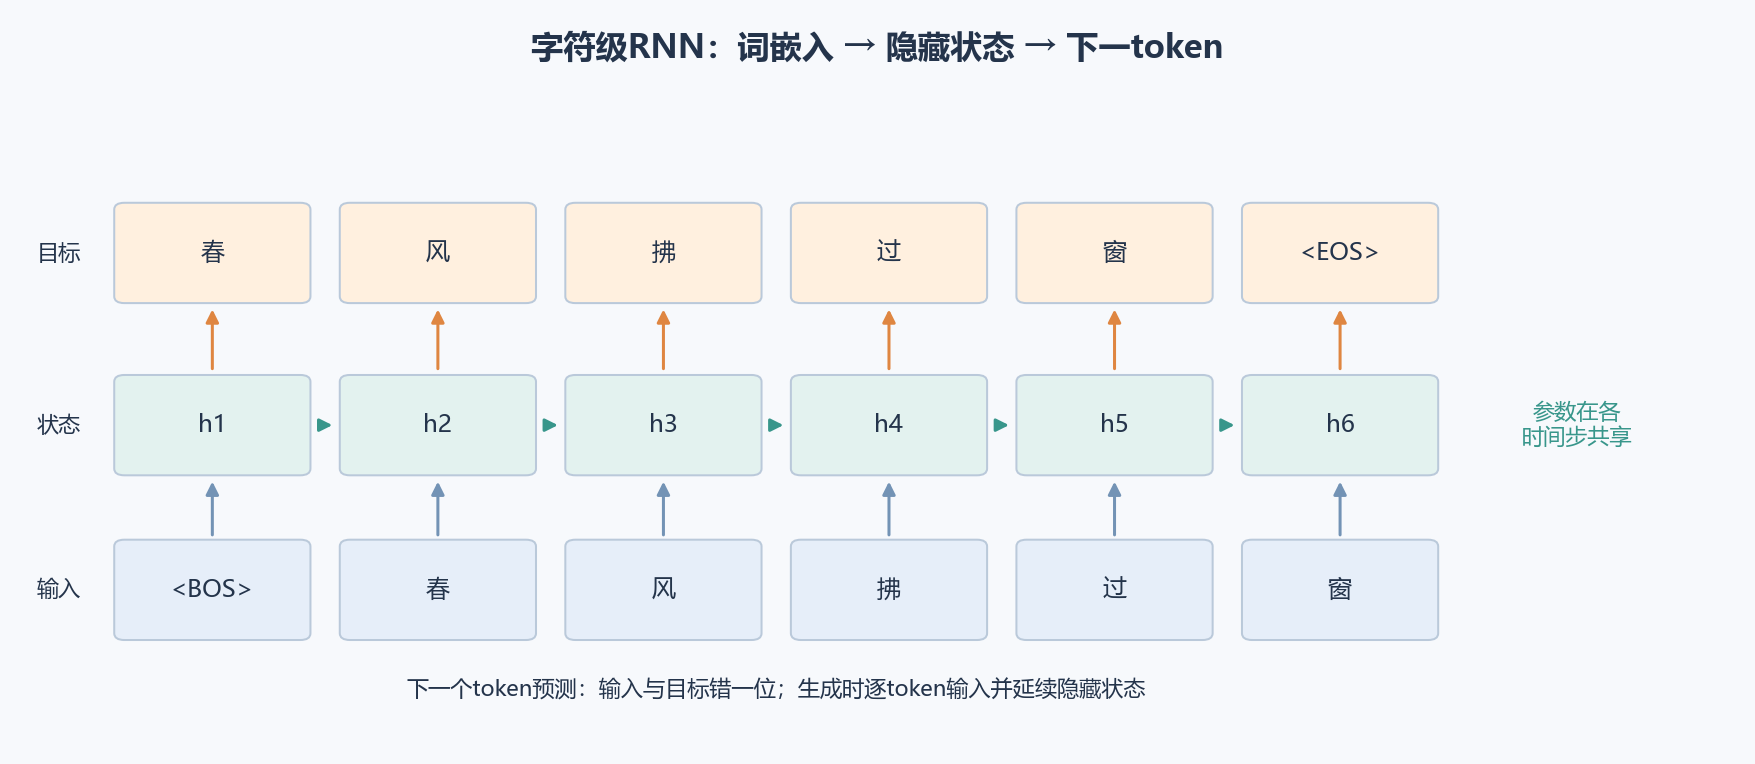

例子中输入“`<BOS> 春 风 拂 过 窗`”，目标整体向左错一位：“`春 风 拂 过 窗 <EOS>`”。每个时间步的输出都用来预测下一token。`<BOS>`表示开始，`<EOS>`表示结束。

循环结构能建模顺序，但普通RNN处理长距离依赖仍可能出现梯度消失或爆炸。LSTM、GRU通过门控缓解部分困难，Transformer则采用另一种序列建模结构；这些不属于本篇已核对的day07目录重点。


## 11. Embedding：ID是索引，向量是参数

本篇按中文字符切分，因此“春风”是两个token。token也可以是词或子词，具体取决于分词方案。`nn.Embedding(V,E)`包含一张可训练矩阵，shape为`(词表大小,嵌入维度)`。

```python
torch.manual_seed(SEED)
embedding_demo = nn.Embedding(num_embeddings=8, embedding_dim=6, padding_idx=0)
token_ids = torch.tensor([[2, 4, 5, 4], [2, 6, 0, 0]], dtype=torch.long)
embedded = embedding_demo(token_ids)
print("IDs:", tuple(token_ids.shape), "vectors:", tuple(embedded.shape))
assert embedded.shape == (2, 4, 6)
assert torch.equal(embedded[0, 1], embedded[0, 3])
assert torch.equal(embedded[1, 2], torch.zeros(6))

embedding_demo.zero_grad(set_to_none=True)
embedded.sum().backward()
assert torch.equal(embedding_demo.weight.grad[0], torch.zeros(6))
assert torch.equal(embedding_demo.weight.grad[4], torch.full((6,), 2.0))
print("embedding parameters:", embedding_demo.weight.numel())
```

- 输入必须是整数索引，且处于`0..V-1`；输入shape可以是`(B,T)`。
- 输出在末尾增加嵌入维度，得到`(B,T,E)`。
- 同一token查到同一行，重复出现会把梯度累加到同一行。
- `padding_idx=0`让该行在本例中保持初始化的零向量并不通过查表反传更新；它**不会自动忽略RNN对PAD时间步的计算**。

ID的数值大小没有语义顺序：ID为7不代表它比ID为3更强或更相近。随机初始化的向量也不天然包含语义关系，需要训练或使用预训练参数。


## 12. nn.RNN的输入、输出和最终状态

```python
torch.manual_seed(SEED)
rnn_demo = nn.RNN(input_size=6, hidden_size=8, num_layers=2,
                  batch_first=True)
sequence_vectors = torch.randn(2, 4, 6)
h0 = torch.zeros(2, 2, 8)
rnn_output, h_n = rnn_demo(sequence_vectors, h0)
print("output:", tuple(rnn_output.shape), "h_n:", tuple(h_n.shape))
assert rnn_output.shape == (2, 4, 8)
assert h_n.shape == (2, 2, 8)
assert torch.allclose(rnn_output[:, -1, :], h_n[-1], atol=1e-6)

# 单方向RNN：分段传递隐藏状态应与连续处理得到相同结果。
first_output, first_hidden = rnn_demo(sequence_vectors[:, :2], h0)
second_output, second_hidden = rnn_demo(sequence_vectors[:, 2:], first_hidden)
assert torch.allclose(torch.cat([first_output, second_output], dim=1),
                      rnn_output, atol=1e-6)
assert torch.allclose(second_hidden, h_n, atol=1e-6)
```

| 符号 | 含义 | 本例 |
| --- | --- | --- |
| B | batch样本数 | 2 |
| T | 时间步数 | 4 |
| E | 每个时间步输入的向量维度 | 6 |
| H | 隐藏状态维度 | 8 |
| L | 层数 | 2 |

`batch_first=True`使输入和`output`为`(B,T,特征维度)`；它**不改变**`h0`和`h_n`的布局，隐藏状态仍是`(L×D,B,H)`，D为方向数。本例D=1。默认`batch_first=False`时，输入为`(T,B,E)`。

`output`包含最上层在每个时间步的输出；`h_n`包含各层、各方向的最后状态。本例单方向下，`output[:,-1,:]`等于`h_n[-1]`。双向RNN有不同的时间对应关系，不能直接照搬这个等式。

未传`h0`时，PyTorch使用零状态。独立短句之间应重置状态；同一段文字逐token生成时可以延续状态。


## 13. 用一次手算核对RNN更新公式

PyTorch的RNN分别提供输入偏置和隐藏状态偏置。下面使用单层RNN的实际参数，核对第一个时间步的tanh更新。

```python
torch.manual_seed(SEED)
one_layer_rnn = nn.RNN(input_size=6, hidden_size=8, batch_first=True)
one_step_x = torch.randn(2, 1, 6)
one_step_h0 = torch.randn(1, 2, 8)
one_step_output, one_step_hn = one_layer_rnn(one_step_x, one_step_h0)
manual_hidden = torch.tanh(
    F.linear(one_step_x[:, 0], one_layer_rnn.weight_ih_l0,
             one_layer_rnn.bias_ih_l0)
    + F.linear(one_step_h0[0], one_layer_rnn.weight_hh_l0,
               one_layer_rnn.bias_hh_l0)
)
assert torch.allclose(manual_hidden, one_step_output[:, 0], atol=1e-6)
assert torch.allclose(manual_hidden, one_step_hn[0], atol=1e-6)
print("RNN single-step check passed")
```

单层单方向RNN参数量为`H×E + H×H + 2H`。输入维度6、隐藏维度8时，共`48+64+16=128`个参数；输出分类头和Embedding参数需要另外计算。


## 14. 歌词生成任务：预测下一个字符

本例只使用下面这些**自编短句**，演示语言模型的训练机制。数据很少，生成结果可能复述训练句、重复字符或提前结束，不能据此评价真实歌词创作能力。

先按完整短句划分训练和验证，再构建词表与窗口。若先把全部文本切成高度重叠的窗口再随机切分，几乎相同的上下文可能同时进入训练和验证，导致评价过于乐观。

```python
lyric_lines = [
    "春风拂过窗边的花", "春风吹来远方的信", "春风轻轻唱着歌", "春风带我走向晨光",
    "夜色落在安静的街", "夜色藏着温柔的梦", "夜色陪我听雨声", "夜色点亮远方的灯",
    "月光洒在清澈的河", "月光照着回家的路", "月光轻轻拥抱晚风", "月光写下心中的歌",
    "我把思念写成一首歌", "我把星光放进你的梦", "我把清晨留在窗前", "我把回忆交给晚风",
    "晚风送来花开的消息", "晚风吹过长长的路", "晚风陪我慢慢歌唱", "晚风带走昨日的雨",
    "星光落在你的眼中", "星光照亮安静的城", "星光陪着远方的梦", "星光点亮心中的灯",
    "雨声敲响窗边的梦", "雨声唱着温柔的歌", "雨声陪我走过长街", "雨声带来花开的清晨",
    "晨光照着窗边的花", "晨光带来温柔的风", "晨光陪我走向远方", "晨光点亮心中的梦",
    "花开时我听见你的歌", "花开时晚风轻轻吹", "花开时星光落在河边", "花开时我们走向晨光",
    "远方有你写下的信", "远方有我心中的梦", "远方传来温柔的歌", "远方亮着回家的灯",
]
line_indices = np.arange(len(lyric_lines))
lyric_train_idx, lyric_val_idx = train_test_split(
    line_indices, test_size=0.2, random_state=SEED
)
train_lines = [lyric_lines[i] for i in lyric_train_idx]
val_lines = [lyric_lines[i] for i in lyric_val_idx]
assert set(lyric_train_idx).isdisjoint(lyric_val_idx)
print("train lines:", len(train_lines), "validation lines:", len(val_lines))
```

这里保留32条训练句、8条验证句，未建立独立测试集。验证结果仅用于教学模型的轮次选择；许多句子共享短语，仍比开放文本场景简单得多。实际项目应按歌曲或文档划分，去除重复文本，并另外保留测试数据。


## 15. 词表：只从训练文本获取字符

先定义特殊token，再给训练集字符分配稳定ID。`<UNK>`处理词表外字符，`<PAD>`补齐窗口，`<BOS>/<EOS>`表示句子边界。推理时必须使用训练时保存的同一词表，不能重新排序生成ID。

```python
SPECIAL_TOKENS = ["<PAD>", "<UNK>", "<BOS>", "<EOS>"]
PAD, UNK, BOS, EOS = range(4)
train_characters = sorted(set("".join(train_lines)))
itos = SPECIAL_TOKENS + train_characters
stoi = {token: i for i, token in enumerate(itos)}
VOCAB_SIZE = len(itos)

def encode_text(text):
    return [stoi.get(char, UNK) for char in text]

def decode_ids(ids):
    return "".join(itos[int(i)] for i in ids)

encoded_demo = encode_text("春风")
print("vocabulary size:", VOCAB_SIZE)
print("春风:", encoded_demo, "decoded:", decode_ids(encoded_demo))
unknown_val_chars = sum(char not in stoi for line in val_lines for char in line)
val_char_count = sum(len(line) for line in val_lines)
print("validation unknown characters:", unknown_val_chars, "/", val_char_count)
assert encode_text("Ω") == [UNK]
assert itos[PAD] == "<PAD>" and stoi["<EOS>"] == EOS
assert len(set(itos)) == VOCAB_SIZE
```

为了稳定复现，字符使用`sorted`排序。如果以后调整文本清洗、分词方案或特殊token顺序，词表可能发生变化，旧权重便不能直接和新词表混用。验证集的词表外字符映射为UNK，不能为了提高验证成绩把它们补进训练词表。


## 16. 滑动窗口：输入和目标错开一个位置

设窗口长度T=8。对每条短句添加BOS和EOS后，逐位置取最多T+1个token；前T个是输入，后T个是目标。末尾不足T的部分用PAD补齐。所有窗口独立，不跨越短句边界。

```python
SEQ_LEN = 8

def build_windows(lines, seq_len):
    inputs, targets = [], []
    for line in lines:
        ids = [BOS] + encode_text(line) + [EOS]
        for start in range(len(ids) - 1):
            segment = ids[start:start + seq_len + 1]
            x, y = segment[:-1], segment[1:]
            inputs.append(x + [PAD] * (seq_len - len(x)))
            targets.append(y + [PAD] * (seq_len - len(y)))
    return TensorDataset(
        torch.tensor(inputs, dtype=torch.long),
        torch.tensor(targets, dtype=torch.long),
    )

lyric_train_ds = build_windows(train_lines, SEQ_LEN)
lyric_val_ds = build_windows(val_lines, SEQ_LEN)
lyric_train_loader = DataLoader(
    lyric_train_ds, batch_size=64, shuffle=True,
    generator=torch.Generator().manual_seed(SEED)
)
lyric_val_loader = DataLoader(lyric_val_ds, batch_size=128, shuffle=False)

toy_ds = build_windows(["春风"], 4)
toy_x, toy_y = toy_ds[0]
assert toy_x.tolist() == [BOS, stoi["春"], stoi["风"], PAD]
assert toy_y.tolist() == [stoi["春"], stoi["风"], EOS, PAD]
print("toy input:", decode_ids(toy_x))
print("toy target:", decode_ids(toy_y))
print("window counts:", len(lyric_train_ds), len(lyric_val_ds))
assert lyric_train_ds.tensors[0].shape[1] == SEQ_LEN
next_inputs = lyric_train_ds.tensors[0][:, 1:]
preceding_targets = lyric_train_ds.tensors[1][:, :-1]
assert torch.all(next_inputs[next_inputs.ne(PAD)] ==
                 preceding_targets[next_inputs.ne(PAD)])
```

这些窗口高度重叠，因此窗口数不是独立歌词的数量，一个字符可能在不同上下文长度下重复参与损失。本例是窗口级教学目标，而不是对整份语料每个字符只计算一次的标准文档级评价。

PAD只出现在尾部。忽略PAD目标的损失即可屏蔽无效输出位置；RNN仍会计算PAD输入的后续状态。本例不把这些尾部最终状态用于分类或传给下一个窗口，所以不会污染有效位置。变长序列分类若使用最后隐藏状态，应使用有效长度或打包序列等处理。


## 17. 生成模型：Embedding → RNN → Linear

RNN每个时间步输出H维向量，Linear对每个位置独立映射成V维logits。因此输出shape是`(B,T,V)`，不是一个batch只输出一个类别。

```python
class CharRNN(nn.Module):
    def __init__(self, vocab_size, embedding_dim=24, hidden_size=64):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=PAD)
        self.rnn = nn.RNN(embedding_dim, hidden_size,
                          num_layers=1, batch_first=True)
        self.head = nn.Linear(hidden_size, vocab_size)

    def forward(self, token_ids, hidden=None):
        vectors = self.embedding(token_ids)
        output, next_hidden = self.rnn(vectors, hidden)
        return self.head(output), next_hidden

torch.manual_seed(SEED)
lyric_config = {"vocab_size": VOCAB_SIZE, "embedding_dim": 24, "hidden_size": 64}
lyric_model = CharRNN(**lyric_config).to(device)
lyric_x, lyric_y = next(iter(lyric_train_loader))
lyric_logits, lyric_hidden = lyric_model(lyric_x.to(device))
assert lyric_logits.shape == (len(lyric_x), SEQ_LEN, VOCAB_SIZE)
assert lyric_hidden.shape == (1, len(lyric_x), 64)
print("logits:", tuple(lyric_logits.shape), "hidden:", tuple(lyric_hidden.shape))
print("parameters:", sum(p.numel() for p in lyric_model.parameters()))
```

这里的Linear可以直接接收三维张量，自动作用在最后一维。训练不必在Python中逐字符调用RNN；把整个窗口一次交给`nn.RNN`即可。逐token调用用于后面的自回归推理。


## 18. 序列损失：忽略PAD，按有效token统计

交叉熵要求类别维与输入约定一致。本例把`(B,T,V)`展平为`(B×T,V)`，把目标展平为`(B×T,)`。用`ignore_index=PAD`屏蔽填充目标，再按有效目标token数计算平均损失与准确率。

```python
lyric_loss_sum_fn = nn.CrossEntropyLoss(ignore_index=PAD, reduction="sum")
lyric_optimizer = torch.optim.Adam(lyric_model.parameters(), lr=3e-3)

def run_lyric_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, total_correct, total_tokens = 0.0, 0, 0
    context = torch.enable_grad() if training else torch.inference_mode()
    with context:
        for token_x, token_y in loader:
            token_x, token_y = token_x.to(device), token_y.to(device)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits, _ = model(token_x)  # 每个独立窗口使用零初始状态
            valid_mask = token_y.ne(PAD)
            valid_count = int(valid_mask.sum())
            summed_loss = lyric_loss_sum_fn(
                logits.reshape(-1, VOCAB_SIZE), token_y.reshape(-1)
            )
            mean_loss = summed_loss / valid_count
            if training:
                mean_loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
            total_loss += float(summed_loss.detach())
            total_correct += int(((logits.argmax(dim=-1) == token_y)
                                  & valid_mask).sum())
            total_tokens += valid_count
    avg_loss = total_loss / total_tokens
    return {"loss": avg_loss, "accuracy": total_correct / total_tokens,
            "perplexity": math.exp(avg_loss), "tokens": total_tokens}

# 核对损失屏蔽：PAD位置不影响总损失。
with torch.no_grad():
    probe_logits = torch.randn(1, 3, VOCAB_SIZE)
    probe_y = torch.tensor([[stoi["春"], EOS, PAD]])
    masked_loss = lyric_loss_sum_fn(probe_logits.reshape(-1, VOCAB_SIZE),
                                    probe_y.reshape(-1))
    unpadded_loss = F.cross_entropy(probe_logits[:, :2].reshape(-1, VOCAB_SIZE),
                                    probe_y[:, :2].reshape(-1), reduction="sum")
    assert torch.allclose(masked_loss, unpadded_loss)
```

自然对数交叉熵对应的困惑度为：

$$\operatorname{PPL}=\exp\!\left(\frac{\sum_{\text{有效位置}}\ell_t}{\text{有效token数}}\right)$$

PPL越低通常表示对这些目标token赋予的概率越高，不能把它当作文采评分。本例窗口重叠、语料很小、词表外字符被折叠成UNK，所以这里的PPL不能和公开语言模型榜单横向比较。

反向传播沿时间依赖计算，通常称为BPTT。梯度裁剪在`backward()`之后、`optimizer.step()`之前执行，限制梯度整体范数；它可缓解梯度爆炸，不能自动解决梯度消失或数据问题。


## 19. 训练歌词模型，保留验证损失最低的轮次

本例训练100轮。每批独立窗口都从零隐藏状态开始，不在打乱后的batch之间传递状态。训练使用真实前一个token作为输入，这通常称为teacher forcing；生成时输入的是模型自己刚生成的token，两者的上下文分布可能不同。

```python
LYRIC_EPOCHS = 100
lyric_history = []
lyric_best = {"loss": float("inf"), "epoch": 0, "state": None}
for epoch in range(1, LYRIC_EPOCHS + 1):
    train_metrics = run_lyric_epoch(lyric_model, lyric_train_loader, lyric_optimizer)
    val_metrics = run_lyric_epoch(lyric_model, lyric_val_loader)
    lyric_history.append({
        "epoch": epoch, "train_loss": train_metrics["loss"],
        "val_loss": val_metrics["loss"],
        "train_accuracy": train_metrics["accuracy"],
        "val_accuracy": val_metrics["accuracy"],
    })
    if val_metrics["loss"] < lyric_best["loss"]:
        lyric_best = {"loss": val_metrics["loss"], "epoch": epoch,
                      "state": copy.deepcopy(lyric_model.state_dict())}
    if epoch == 1 or epoch % 25 == 0:
        print(epoch, "train loss:", round(train_metrics["loss"], 4),
              "val loss:", round(val_metrics["loss"], 4),
              "val PPL:", round(val_metrics["perplexity"], 3))

lyric_model.load_state_dict(lyric_best["state"])
lyric_selected_val = run_lyric_epoch(lyric_model, lyric_val_loader)
print("selected epoch:", lyric_best["epoch"],
      "validation loss:", round(lyric_selected_val["loss"], 4))
```

小语料训练损失很容易降得很低，而验证损失可能提前上升。应依据验证表现选择轮次，并检查具体生成文本。对未知前缀与长文本的能力，不能由训练集准确率推断。


## 20. 逐字符生成：先读前缀，再延续状态

生成时先一次读入`BOS + 前缀`，用最后位置的logits决定下一字符。随后每次只输入一个新token，并沿用上一步隐藏状态。把完整前缀反复输入又同时沿用旧状态，会重复消费上下文。

greedy每次取分数最高的token。采样则按概率抽取，能得到更多变化。生成时屏蔽PAD、UNK和BOS，保留EOS作为正常停止条件。

```python
@torch.inference_mode()
def generate_lyric(model, prefix, max_new_tokens=20,
                   strategy="greedy", temperature=1.0, seed=0):
    if strategy not in {"greedy", "sample"}:
        raise ValueError("strategy应为greedy或sample")
    if temperature <= 0:
        raise ValueError("temperature必须大于0")
    if max_new_tokens < 0:
        raise ValueError("max_new_tokens不能为负数")
    if any(char not in stoi for char in prefix):
        raise ValueError("此前缀包含词表外字符，请更换前缀")
    model.eval()
    model_device = next(model.parameters()).device
    # 本篇在CPU采样，局部随机生成器使示例可重复。
    rng = torch.Generator(device="cpu").manual_seed(seed)
    ids = [BOS] + encode_text(prefix)
    token_x = torch.tensor([ids], dtype=torch.long, device=model_device)
    logits, hidden = model(token_x)
    generated_ids = []
    for _ in range(max_new_tokens):
        scores = logits[0, -1].clone()
        scores[[PAD, UNK, BOS]] = -float("inf")
        if strategy == "greedy":
            next_id = int(scores.argmax())
        else:
            probabilities = (scores / temperature).softmax(dim=-1).cpu()
            next_id = int(torch.multinomial(probabilities, 1, generator=rng))
        if next_id == EOS:
            break
        generated_ids.append(next_id)
        token_x = torch.tensor([[next_id]], dtype=torch.long, device=model_device)
        logits, hidden = model(token_x, hidden)
    return prefix + decode_ids(generated_ids)

generated_examples = []
for prefix in ["春风", "夜色", "我把"]:
    greedy_text = generate_lyric(lyric_model, prefix, strategy="greedy")
    sampled_text = generate_lyric(lyric_model, prefix, strategy="sample",
                                  temperature=0.9, seed=7)
    generated_examples.append({"prefix": prefix, "greedy": greedy_text,
                                "sample": sampled_text})
    print("prefix:", prefix, "greedy:", greedy_text, "sample:", sampled_text)
assert generate_lyric(lyric_model, "春风", max_new_tokens=0) == "春风"
assert generate_lyric(lyric_model, "春风", strategy="sample", seed=7) == \
       generate_lyric(lyric_model, "春风", strategy="sample", seed=7)
```

`max_new_tokens`仅限制新增字符，不包含前缀。EOS被预测到就停止，输出中不显示特殊token。普通RNN无法看到尚未生成的字符；若用双向网络读取完整训练窗口，会把未来输入泄露给预测位置，不能直接作为这里的因果生成模型。


## 21. 温度：改变采样分布，不改变模型权重

设logits为$z_i$，正温度为$\tau$：

$$p_i(\tau)=\frac{\exp(z_i/\tau)}{\sum_j\exp(z_j/\tau)},\qquad \tau>0$$

- 温度低于1：分布更集中，倾向高分token。
- 温度等于1：使用原Softmax分布。
- 温度高于1：分布更平缓，候选更分散，错误和重复也可能增多。

温度作用于采样概率。对于正温度，仅缩放logits不会改变argmax，greedy的选择不受温度影响。温度为0不能直接代入公式，可用greedy表达确定性选择。

```python
temperature_demo = [0.6, 1.0, 1.4]
with torch.inference_mode():
    prefix_ids = torch.tensor([[BOS] + encode_text("春风")], dtype=torch.long)
    prefix_logits, _ = lyric_model.eval()(prefix_ids)
    next_scores = prefix_logits[0, -1].clone()
    next_scores[[PAD, UNK, BOS]] = -float("inf")
    temperature_probabilities = torch.stack([
        (next_scores / temperature).softmax(dim=-1)
        for temperature in temperature_demo
    ])
    top_ids = torch.topk(temperature_probabilities[1], k=6).indices
    assert torch.allclose(temperature_probabilities.sum(dim=1), torch.ones(3))
    assert all(int((next_scores / t).argmax()) == int(next_scores.argmax())
               for t in temperature_demo)

temperature_texts = [
    generate_lyric(lyric_model, "春风", strategy="sample",
                   temperature=t, seed=11)
    for t in temperature_demo
]
for t, text in zip(temperature_demo, temperature_texts):
    print("temperature:", t, "generated:", text)
```

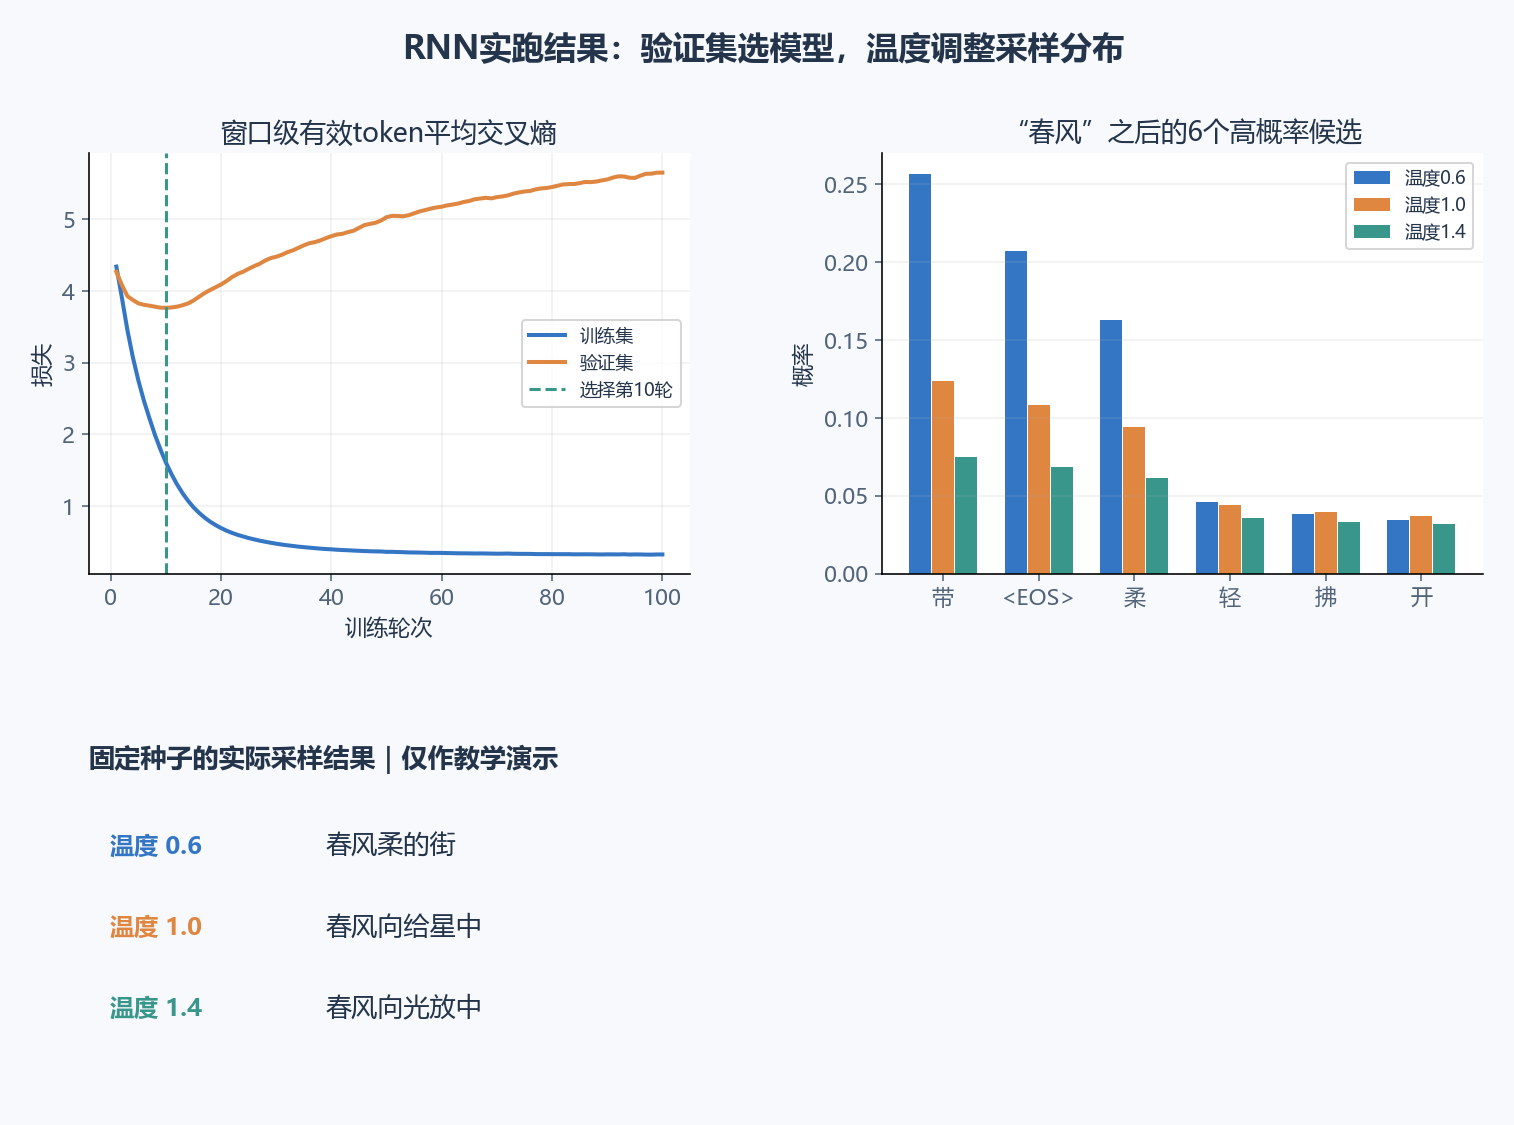

图中只展示同一前缀下概率最高的6个候选，因此这些柱子的和通常小于1。生成文本来自上述模型和固定随机种子，只展示教学模型的行为；更高温度不保证更有创意，更低温度也不保证句子更正确。


## 22. 保存RNN：权重与词表必须配套

RNN的Embedding行、输出Linear的行与词表ID一一对应。模型加载时，配置和词表一起恢复。本例词表在同一运行会话中保持不变，先检查加载词表一致，再核对输出。

```python
lyric_checkpoint = {
    "state_dict": {k: v.detach().cpu() for k, v in lyric_model.state_dict().items()},
    "config": lyric_config,
    "itos": itos,
    "special_ids": {"pad": PAD, "unk": UNK, "bos": BOS, "eos": EOS},
    "tokenization": "character",
    "seq_len": SEQ_LEN,
    "selected_epoch": lyric_best["epoch"],
}
lyric_buffer = io.BytesIO()
torch.save(lyric_checkpoint, lyric_buffer)
lyric_buffer.seek(0)
loaded_lyric = torch.load(lyric_buffer, map_location="cpu", weights_only=True)
assert loaded_lyric["itos"] == itos
assert loaded_lyric["special_ids"] == {"pad": PAD, "unk": UNK, "bos": BOS, "eos": EOS}
restored_lyric = CharRNN(**loaded_lyric["config"]).eval()
restored_lyric.load_state_dict(loaded_lyric["state_dict"])
with torch.inference_mode():
    probe_ids = torch.tensor([[BOS] + encode_text("春风")], dtype=torch.long)
    original_logits, original_hidden = lyric_model.eval()(probe_ids)
    restored_logits, restored_hidden = restored_lyric(probe_ids)
    assert torch.allclose(original_logits, restored_logits, atol=1e-6)
    assert torch.allclose(original_hidden, restored_hidden, atol=1e-6)
assert generate_lyric(lyric_model, "春风") == generate_lyric(restored_lyric, "春风")
print("RNN checkpoint roundtrip passed")
```

实际另起进程推理时，应从checkpoint重建`itos/stoi`和特殊token ID，把编码、解码也绑定到同一份词表。本篇为便于阅读把这些映射保留为全局变量，所以不能一边加载另一份词表的模型、一边复用旧映射。

这里保存的是推理checkpoint。如果需要接着训练，还应保存优化器、学习率调度器状态和训练进度；仅恢复模型权重不能完整恢复优化轨迹。


## 23. 两个案例的实跑记录

以下数值来自本篇示例代码的CPU运行，固定种子为2026。版本、设备或数据划分改变后，结果可能变化。

| CNN图像分类 | 实跑结果 |
| --- | --- |
| 数据 | sklearn digits，1797张8×8灰度图，10类 |
| 训练/验证/测试样本数 | 1078 / 359 / 360 |
| 网络参数量、训练轮数 | 13706；40轮 |
| 验证损失最佳轮次 | 第40轮 |
| 所选模型的验证损失/准确率 | 0.1427 / 95.82% |
| 最终测试损失/准确率 | 0.0931 / 97.50% |

| RNN字符生成 | 实跑结果 |
| --- | --- |
| 自编训练/验证短句数 | 32 / 8 |
| 训练/验证窗口数 | 290 / 75 |
| 词表大小（含4个特殊token） | 85 |
| 网络参数量、训练轮数 | 13325；100轮 |
| 验证集词表外字符数 | 11 / 67 |
| 验证损失最佳轮次 | 第10轮 |
| 所选模型的验证交叉熵/困惑度 | 3.7668 / 43.241 |
| 所选模型的验证token准确率 | 26.33% |

生成示例（采样温度0.9，种子7）：

| 前缀 | greedy | 概率采样 |
| --- | --- | --- |
| 春风 | 春风带我走向晨光 | 春风首走向晨光 |
| 夜色 | 夜色落在安静的梦 | 夜色首昨念消安吹着回你 |
| 我把 | 我把风轻轻吹 | 我把首昨念色来听柔的你 |

CNN测试集只用于最终评估；RNN未设置独立测试集，验证指标基于重叠窗口，不代表公开歌词语料或真实创作能力。


## 24. 常见问题与排查

| 问题 | 原因或检查方向 |
| --- | --- |
| Conv2d要求4维输入 | 灰度图缺通道维，单图还可能缺batch维 |
| 图片看起来正常，分类却很差 | 检查0–16与0–255、HWC与NCHW、灰度与RGB及重复缩放 |
| Linear矩阵不能相乘 | 打印池化后shape，核对Flatten维度 |
| CrossEntropyLoss报标签类型错误 | 类别ID和token目标用long，不能是float |
| Embedding出现index out of range | ID超过词表，加载映射错位，特殊token未计入词表大小 |
| RNN expected hidden size | h0布局为`(层数×方向数,B,H)`，batch_first不改变它 |
| RNN损失几乎不变 | 输入与目标是否移位，是否全为PAD，词表/标签是否对齐 |
| 序列准确率异常高 | 是否把PAD计入正确率，验证窗口是否来自训练文本 |
| 生成只输出前缀 | 第一轮可能预测EOS，检查语料、模型状态和概率分布 |
| 生成全是重复字符 | 小语料过拟合、采样分布过尖、隐藏状态重复消费前缀 |
| 生成语句混乱 | 温度、词表、训练不足、状态管理和数据量都可能影响 |
| PAD行没梯度但结果仍受填充影响 | padding_idx只作用于Embedding，RNN仍更新隐藏状态 |
| 重启后生成完全不同 | 检查权重、词表顺序、分词规则、模型模式和采样种子 |

调试顺序建议：先打印shape和数值范围，再核对标签/词表，接着检查损失和梯度，最后调整网络与学习率。复杂模型不能补救错误的数据流。


## 25. 练习与参考答案

1. 输入图像shape为`(16,1,8,8)`，经过本例features与classifier，各自输出shape是什么？
2. 为什么模型选择不能看测试准确率，为什么验证损失最低的轮次可能不是验证准确率最高的轮次？
3. `nn.Embedding(100,24)`接收`(32,8)`的ID张量，输出shape和参数量是多少？
4. 双层单方向RNN，B=32、T=8、E=24、H=64、batch_first=True，output和h_n是什么shape？
5. 为什么不能先构造歌词重叠窗口再随机切分训练和验证？
6. 为什么PAD位置需要忽略损失，也需要在计算准确率时忽略？
7. 逐字符生成时，隐藏状态要保留还是清零？如果每轮都重新读完整前缀呢？
8. 温度从1升到1.4，greedy一定会变吗？采样文本一定更好吗？

参考答案：

- 第1题：features输出`(16,32,2,2)`；classifier输出`(16,10)`。
- 第2题：测试参与选择会污染最终评估。交叉熵关注真实类别的概率与置信度，准确率只看argmax对错，两者排序可能不同。
- 第3题：`(32,8,24)`；参数量`100×24=2400`，其中PAD行即使不更新也计入张量元素数。
- 第4题：output为`(32,8,64)`，h_n为`(2,32,64)`；第二个维度才是batch。
- 第5题：相邻窗口共享大部分字符，随机切分会让非常相似的上下文跨集合。应先按歌曲/文档切分，再分别构建窗口。
- 第6题：PAD是为了补齐shape，不是真实语言目标；把它计入会扭曲损失与准确率。
- 第7题：每轮只输入新token时保留状态。如果从头重读完整前缀，应从零状态开始，避免重复消费同一段上下文。
- 第8题：正温度缩放不改变argmax，所以greedy不变。采样更分散但质量不保证提升。

进一步实践：用验证集比较CNN的不同学习率；绘制误分类图；将CharRNN改为GRU并保持相同划分、词表、窗口和评价口径；增加自编文本后观察训练/验证曲线与生成变化。比较不同结构时也应记录参数量与训练预算。


## 26. 速查：形状、损失与状态

| 任务/组件 | 关键约定 |
| --- | --- |
| CNN图像输入 | `(B,C,H,W)`，float32，缩放与训练一致 |
| CNN分类输出 | `(B,C_classes)` logits，目标`(B,)` long |
| 数据划分 | train更新，val选模型，test最终评估 |
| Embedding | `(B,T)`整数ID → `(B,T,E)` |
| RNN batch_first=True | `(B,T,E)` → output `(B,T,H×D)` |
| RNN最终隐藏状态 | `(L×D,B,H)`，不受batch_first影响 |
| 字符生成头 | `(B,T,H)` → `(B,T,V)` logits |
| 序列交叉熵 | 展平为`(B×T,V)`与`(B×T,)`，忽略PAD |
| 序列指标 | 按有效token数汇总，不计PAD |
| 独立窗口训练 | 每个窗口零初始状态；打乱batch不延续状态 |
| 单token自回归生成 | 读一次前缀，随后逐token输入并延续状态 |
| 梯度裁剪 | backward之后、optimizer.step之前 |
| greedy | argmax，正温度不改变选择 |
| 温度采样 | softmax(logits/temperature)，temperature>0 |
| 推理保存 | 结构配置、权重、词表/类别映射、预处理规则 |

到这里，day01–day07的学习路径形成了完整链条：张量与自动微分 → 网络、损失和优化 → 表格分类 → 卷积与池化 → 图像分类 → 序列建模与字符生成。


## 27. day07目录与资料范围

本次已核对的17个视频文件标题：

| 序号 | 视频标题主题 |
| --- | --- |
| 01 | 今日内容大纲介绍 |
| 02 | CNN图像分类案例_准备数据集 |
| 03 | CNN图像分类案例_搭建神经网络_思路分析 |
| 04 | CNN图像分类案例_搭建神经网络_代码实现 |
| 05 | CNN图像分类案例_模型训练 |
| 06 | CNN图像分类案例_模型测试 |
| 07 | CNN图像分类案例_优化及总结 |
| 08 | RNN介绍 |
| 09 | 词嵌入层_解释 |
| 10 | 词嵌入层_API演示 |
| 11 | RNN层(循环网络层)_简介 |
| 12 | RNN层(循环网络层)_API演示 |
| 13 | RNN_AI歌词生成器案例_构建词表 |
| 14 | RNN_AI歌词生成器案例_构建数据集 |
| 15 | RNN_AI歌词生成器案例_搭建神经网络 |
| 16 | RNN_AI歌词生成器案例_模型训练 |
| 17 | RNN_AI歌词生成器案例_模型测试 |

**范围说明：**目录标题用于确定主题顺序；教师压缩包、课程代码和原始数据正文未取得，未逐段转录视频。digits示例、自编歌词短句、训练参数、推理策略和5张图均为本文独立教学补充，不应视为课程原代码、原歌词或课堂成绩。

API与数据可查：

- [PyTorch Conv2d](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html)
- [PyTorch Embedding](https://docs.pytorch.org/docs/stable/generated/torch.nn.Embedding.html)
- [PyTorch RNN](https://docs.pytorch.org/docs/stable/generated/torch.nn.RNN.html)
- [PyTorch CrossEntropyLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html)
- [scikit-learn load_digits](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html)
